# TAF Optimización · Optimizador de la grilla del Lollapalooza Argentina 2026
**Licenciatura en Ciencia de Datos · Optimización (2025)**

**Problema.** Dada la lista de 72 artistas confirmados, 3 jornadas y 4 escenarios, decidir *qué artista toca qué día, en qué escenario y a qué hora* para **minimizar la superposición de artistas similares** (que compiten por la misma audiencia), sin romper las restricciones operativas del festival, y compararlo con la grilla realmente anunciada.

**Enfoque.** Programación con restricciones (CP-SAT de OR-Tools) sobre variables binarias y enteras, con una matheurística de 3 fases. La grilla real se usa como *línea base*: todos los indicadores se expresan relativos a ella.

**Contenido:** 0. Preparación · 1. Formulación · 2. Datos y exploración · 3. Costos · 4. Evaluación y línea base · 5. Modelo CP-SAT · 6. Resolución y resultados · 7. Sensibilidad y robustez · 8. Exportación y conclusiones.

## 0. Preparación


In [1]:
!pip -q install ortools openpyxl
import os
TIME_LIMIT = 120        # segundos para la optimización principal (por semilla)
TIME_SENS  = 90         # segundos por escenario en sensibilidad
SEEDS      = (1, 2, 3)  # semillas de la corrida principal (variabilidad del método); (1,) para ir rápido
try:
    from google.colab import files
    up = files.upload()
    DATA_PATH = list(up.keys())[0]
except ImportError:
    DATA_PATH = 'lollapalooza_2026_dataset_completo_popularidad.xlsx'
print('Usando:', DATA_PATH)

Saving lollapalooza_2026_dataset_completo_popularidad.xlsx to lollapalooza_2026_dataset_completo_popularidad.xlsx
Usando: lollapalooza_2026_dataset_completo_popularidad.xlsx


## 1. Formulación matemática

**Conjuntos.** $I$ artistas (72), $D$ jornadas (3), $S$ escenarios (4), $H\subseteq I$ headliners, $P=\{(i,j): i<j\}$ pares de artistas.

**Parámetros.** $L_i$ duración (en slots de 15 min) · $m_s$ minutos de montaje del escenario $s$ · $[a_{ds},b_{ds}]$ ventana horaria del escenario $s$ en la jornada $d$ · $v_{id}\in\{0,1\}$ disponibilidad · $N^{min}_d,N^{max}_d$ cantidad de artistas por día · $K^{min}_d$ headliners mínimos · $\kappa_s$ capacidad y $q_i$ demanda estimada · $f(\text{pop}_i)$ popularidad transformada.

El costo de que dos artistas coincidan combina similitud musical y popularidad:
$$c_{ij}=\sigma(g_i,g_j)\cdot f(\text{pop}_i)\cdot f(\text{pop}_j),\qquad \sigma\in\{1\ (\text{mismo género}),\ 0.5\ (\text{cercano}),\ 0.1\ (\text{distinto})\}$$

**Variables.** $x_{ids}\in\{0,1\}$: el artista $i$ toca el día $d$ en el escenario $s$ · $t_i\in\mathbb{Z}_{\ge0}$: slot de inicio · $w_{ij}\in\{0,1\}$: $i$ y $j$ tocan el mismo día · $o_{ij}\in\mathbb{Z}_{\ge0}$: slots solapados · $A_d$: atractivo acumulado del día $d$.

**Restricciones.**

1. Asignación única y disponibilidad: $\sum_{d,s}x_{ids}=1$, $\;x_{ids}\le v_{id}$.
2. Ventana horaria: $x_{ids}=1\Rightarrow a_{ds}\le t_i,\; t_i+L_i\le b_{ds}$.
3. Sin superposición ni falta de montaje en un escenario: si $x_{ids}=x_{jds}=1$ entonces $t_i+L_i+m_s\le t_j$ **o** $t_j+L_j+m_s\le t_i$ (`NoOverlap` sobre intervalos opcionales de largo $L_i+m_s$).
4. Cantidad de artistas por día: $N^{min}_d\le\sum_{i,s}x_{ids}\le N^{max}_d$.
5. Headliners: $\sum_{i\in H,s}x_{ids}\ge K^{min}_d$ y $t_i\ge t^{HL}$ para $i\in H$.
6. Capacidad: $x_{ids}=0$ si $q_i>\kappa_s$.
7. Cobertura: en cada bloque horario de 180 min de cada escenario y día, al menos un show arranca allí (evita escenarios vacíos).
8. Mismo día: $w_{ij}=1\iff \sum_s\sum_d d\,x_{ids}=\sum_s\sum_d d\,x_{jds}$.
9. Solapamiento (linealización por mínimo): $o_{ij}\ge \min\{L_i,\,L_j,\,t_i+L_i-t_j,\,t_j+L_j-t_i\}$ si $w_{ij}=1$; $o_{ij}\ge0$.
10. Atractivo diario: $A_d=\sum_i f(\text{pop}_i)\sum_s x_{ids}$.

**Objetivo.** Ambos términos se normalizan con la grilla real ($Z^0_{conf}$, $Z^0_{eq}$), por lo que **1.0 equivale a la grilla anunciada**:
$$\min\; w_{conf}\,\frac{\sum_{(i,j)\in P}c_{ij}\,\tfrac{15}{60}\,o_{ij}}{Z^0_{conf}}\;+\;w_{eq}\,\frac{\max_d A_d-\min_d A_d}{Z^0_{eq}}$$

**Por qué CP-SAT y no un MILP puro.** El solapamiento entre dos shows es una disyunción (restricciones 3 y 9). En un MILP exigiría big-M o variables indexadas por tiempo ($x_{idst}$, ~124 mil binarias a 5 min). CP-SAT maneja intervalos opcionales y `NoOverlap` de forma nativa, con la misma lógica de variables binarias y enteras vista en el curso.

In [2]:
from __future__ import annotations

import io
import math
import time
from dataclasses import dataclass, field, replace

import numpy as np
import pandas as pd
from ortools.sat.python import cp_model

SCALE = 10_000_000  # escala entera de la función objetivo (CP-SAT trabaja con enteros)


# ----------------------------------------------------------------------------
# 1. Configuración y datos
# ----------------------------------------------------------------------------
@dataclass
class Config:
    """Parámetros del modelo. Todo lo que el usuario puede tocar desde la app."""
    slot: int = 15                    # granularidad temporal (min)
    w_conf: float = 1.0               # peso de conflictos
    w_equil: float = 0.2              # peso de equilibrio entre días
    sim_same: float | None = None     # None -> se toma de la hoja Parametros
    sim_near: float | None = None
    sim_far: float | None = None
    pop_transform: str = "lineal"     # lineal | raiz | log
    flexible_days: bool = True        # True: optimiza día; False: conserva el día real
    use_capacity: bool = True         # demanda estimada <= capacidad del escenario
    demand_exponent: float = 1.5      # demanda = pico * cap_max * (pop/100)^exponente (si no hay dato)
    demand_peak: float = 0.9          # el artista más popular llena este % del mayor escenario
    capacity_tol: float = 0.0         # holgura sobre la capacidad (0.1 = +10 %)
    headliner_min_start: int = 1140   # los headliners arrancan a partir de las 19:00
    max_headliners_day: int | None = None
    # palancas para análisis de sensibilidad
    prep_extra: int = 0               # minutos extra de montaje en todos los escenarios
    cap_scale: float = 1.0            # multiplicador de capacidades
    art_delta: int = 0                # relaja min/max de artistas por día (+/-)
    coverage_block: int = 180         # cada escenario debe arrancar >=1 show en cada bloque de N min (0 = sin regla)
    pair_mass: float = 0.97           # fracción del costo total cubierta por los pares modelados (fase 2)
    max_imbalance: float | None = None  # ε-restricción: desequilibrio entre días <= este valor (None = sin tope)


@dataclass
class Data:
    artists: pd.DataFrame
    avail: np.ndarray
    stages: pd.DataFrame
    days: pd.DataFrame
    params: dict
    genre_rel: dict
    notes: list = field(default_factory=list)


class DataError(Exception):
    pass


def _num(v, default=None):
    try:
        return float(v)
    except (TypeError, ValueError):
        return default


def load_data(source) -> Data:
    """Lee el Excel (ruta o archivo subido) y lo normaliza. Valida estructura."""
    try:
        xl = pd.ExcelFile(source)
    except Exception as e:  # noqa: BLE001
        raise DataError(f"No se pudo abrir el Excel: {e}")
    need = ["Artistas_72", "Disponibilidad_dias", "Escenarios", "Dias_y_franjas", "Parametros"]
    miss = [s for s in need if s not in xl.sheet_names]
    if miss:
        raise DataError(f"Faltan hojas obligatorias: {miss}")

    notes = []
    a = xl.parse("Artistas_72")
    need_cols = ["ID_artista", "Artista", "Duracion_min", "Headliner_ref_0_1", "Genero_modelo",
                 "Dia_original", "Escenario_original", "Inicio_min", "Popularidad_Spotify_0_100"]
    miss = [c for c in need_cols if c not in a.columns]
    if miss:
        raise DataError(f"Hoja Artistas_72: faltan columnas {miss}")
    if a["ID_artista"].duplicated().any():
        raise DataError("Hay ID_artista duplicados.")

    # popularidad: índice combinado Spotify+Trends si está completo; si no, Spotify
    if "Popularidad_indice" in a.columns and a["Popularidad_indice"].notna().all():
        pop = a["Popularidad_indice"].astype(float)
        notes.append("Popularidad = índice combinado Spotify+Trends.")
    else:
        pop = a["Popularidad_Spotify_0_100"].astype(float)
        notes.append("Popularidad = Spotify normalizado (Trends no cargado).")
    if pop.isna().any():
        raise DataError("Hay artistas sin popularidad.")

    days = xl.parse("Dias_y_franjas")
    days = pd.DataFrame({
        "label": [f"{str(r.Dia)} {str(r.Fecha)[-2:]}" for r in days.itertuples()],
        "fecha": days["Fecha"].astype(str).str[:10],
        "min_art": days["Min_artistas_EDIT"].astype(int),
        "max_art": days["Max_artistas_EDIT"].astype(int),
        "open": days["Inicio_festival_min_EDIT"].astype(int),
        "close": days["Fin_festival_min_EDIT"].astype(int),
        "min_hl": days["Min_headliners_EDIT"].astype(int),
    })
    fechas = list(days["fecha"])
    day0 = [fechas.index(str(x)[:10]) if str(x)[:10] in fechas else -1 for x in a["Dia_original"]]

    st = xl.parse("Escenarios")
    stages = pd.DataFrame({
        "name": st["Escenario"].astype(str),
        "cap": st["Capacidad_simulada_EDIT"].astype(float),
        "prep": st["Preparacion_min_EDIT"].astype(int),
        "open": st["Horario_inicio_min_EDIT"].astype(int),
        "close": st["Horario_fin_min_EDIT"].astype(int),
    })

    artists = pd.DataFrame({
        "id": a["ID_artista"].astype(str),
        "name": a["Artista"].astype(str),
        "genre": a["Genero_modelo"].astype(str),
        "dur": a["Duracion_min"].astype(int),
        "hl": a["Headliner_ref_0_1"].astype(int),
        "pop": pop.values,
        "day0": day0,
        "stage0": a["Escenario_original"].astype(str),
        "start0": a["Inicio_min"].astype(int),
        "demand": (a["Demanda_estimada_EDIT"].astype(float)
                   if "Demanda_estimada_EDIT" in a.columns else np.nan),
    })

    dv = xl.parse("Disponibilidad_dias")
    cols = [c for c in dv.columns if str(c).endswith("_0_1")]
    if len(cols) != len(days):
        raise DataError("Disponibilidad_dias: la cantidad de columnas *_0_1 debe coincidir con los días.")
    dv = dv.set_index("ID_artista").reindex(artists["id"])
    if dv[cols].isna().any().any():
        raise DataError("Disponibilidad_dias: faltan artistas o hay celdas vacías.")
    avail = dv[cols].astype(int).values
    if (avail.sum(axis=1) == 0).any():
        bad = artists["name"][avail.sum(axis=1) == 0].tolist()
        raise DataError(f"Artistas sin ningún día disponible: {bad}")

    params = {}
    pr = xl.parse("Parametros")
    for r in pr.itertuples():
        v = _num(r.Valor_EDIT)
        params[str(r.Parametro)] = v if v is not None else r.Valor_EDIT

    # relación entre géneros (igual / cercano / distinto) tomada de Pares_similitud
    genre_rel = {}
    if "Pares_similitud" in xl.sheet_names:
        p = xl.parse("Pares_similitud")
        for r in p.itertuples():
            cat = "same" if r.Similitud_sup >= 0.99 else ("near" if abs(r.Similitud_sup - 0.5) < 1e-9 else "far")
            genre_rel[(r.Genero_1, r.Genero_2)] = cat
            genre_rel[(r.Genero_2, r.Genero_1)] = cat
    else:
        notes.append("Sin hoja Pares_similitud: géneros distintos = similitud baja.")

    return Data(artists, avail, stages, days, params, genre_rel, notes)


def validate(data: Data, cfg: Config) -> list[tuple[str, str]]:
    """Chequeos previos. Devuelve lista de (nivel, mensaje)."""
    out = []
    a, d, s = data.artists, data.days, data.stages
    A = len(a)
    if d["min_art"].sum() > A or d["max_art"].sum() < A:
        out.append(("error", f"Los mínimos/máximos por día ({d['min_art'].sum()}–{d['max_art'].sum()}) "
                             f"no permiten ubicar los {A} artistas."))
    if a["hl"].sum() < d["min_hl"].sum():
        out.append(("error", "No hay suficientes headliners para cubrir el mínimo diario."))
    if cfg.max_headliners_day is not None and cfg.max_headliners_day * len(d) < a["hl"].sum():
        out.append(("error", f"Con máx. {cfg.max_headliners_day} headliners por día no entran los {int(a['hl'].sum())} headliners."))
    if (a["start0"] % cfg.slot != 0).any():
        n = int((a["start0"] % cfg.slot != 0).sum())
        out.append(("warn", f"{n} horario(s) real(es) no caen en la grilla de {cfg.slot} min; "
                            f"la grilla real se evalúa en minutos exactos."))
    if (a["dur"] % cfg.slot != 0).any():
        out.append(("warn", "Hay duraciones que no son múltiplo del slot: se redondean hacia arriba en el modelo."))
    if (a["pop"] < 2).sum() > A * 0.3:
        out.append(("warn", f"{int((a['pop'] < 2).sum())} artistas tienen popularidad < 2/100: la normalización "
                            f"por el máximo deja casi sin peso a gran parte de la grilla. Probá transformación 'raiz' o 'log'."))
    if a["demand"].isna().all():
        out.append(("info", "Demanda_estimada vacía: se deriva de la popularidad (ver demand_exponent)."))
    if (data.avail.sum() == data.avail.size):
        out.append(("info", "Todas las disponibilidades están en 1 (supuesto), el modelo tiene máxima libertad."))
    if "Fecha_medicion_popularidad" in data.params and str(data.params["Fecha_medicion_popularidad"]).upper() == "PENDIENTE":
        out.append(("warn", "Falta registrar la fecha de medición de Spotify (trazabilidad del dato)."))
    return out


def coverage_blocks(lo: int, hi: int, B: int) -> list[tuple[int, int]]:
    """Parte la ventana [lo,hi) en bloques de B min (si el último queda < B/2 se fusiona con el anterior)."""
    if B <= 0 or hi - lo < B:
        return []
    cuts = list(range(lo, hi, B))
    if hi - cuts[-1] < B / 2 and len(cuts) > 1:
        cuts.pop()
    return [(c, cuts[k + 1] if k + 1 < len(cuts) else hi) for k, c in enumerate(cuts)]

## 2. Datos y exploración

In [3]:
data = load_data(DATA_PATH)
cfg = Config()
for lvl, msg in validate(data, cfg):
    print(f'[{lvl.upper():5}] {msg}')
print()
print(data.artists.groupby('genre').size().sort_values(ascending=False).to_frame('artistas').T.to_string())
print()
display(data.stages); display(data.days)

[WARN ] 1 horario(s) real(es) no caen en la grilla de 15 min; la grilla real se evalúa en minutos exactos.
[WARN ] Hay duraciones que no son múltiplo del slot: se redondean hacia arriba en el modelo.
[WARN ] 28 artistas tienen popularidad < 2/100: la normalización por el máximo deja casi sin peso a gran parte de la grilla. Probá transformación 'raiz' o 'log'.
[INFO ] Demanda_estimada vacía: se deriva de la popularidad (ver demand_exponent).
[INFO ] Todas las disponibilidades están en 1 (supuesto), el modelo tiene máxima libertad.
[WARN ] Falta registrar la fecha de medición de Spotify (trazabilidad del dato).

genre     Electrónica  Pop  Urbano  Rock  Indie/Alternativo  Funk  Folklore  Cumbia  Otros
artistas           20   17      12     9                  8     2         2       1      1



,name,cap,prep,open,close
0,Flow,45000.0,30,780,1500
1,Samsung,35000.0,30,780,1500
2,Alternative,18000.0,20,780,1500
3,Perrys,12000.0,15,780,1500


,label,fecha,min_art,max_art,open,close,min_hl
0,Viernes 13,2026-03-13,22,26,780,1500,2
1,Sabado 14,2026-03-14,22,26,780,1500,2
2,Domingo 15,2026-03-15,22,26,780,1500,2


## 3. Costos de conflicto

In [4]:
# ----------------------------------------------------------------------------
# 2. Costos
# ----------------------------------------------------------------------------
def pop_factor(data: Data, cfg: Config) -> np.ndarray:
    p = data.artists["pop"].values.astype(float)
    if cfg.pop_transform == "raiz":
        return np.sqrt(p / 100.0)
    if cfg.pop_transform == "log":
        return np.log1p(p) / math.log1p(100.0)
    return p / 100.0


def sim_matrix(data: Data, cfg: Config) -> np.ndarray:
    ss = cfg.sim_same if cfg.sim_same is not None else data.params.get("Similitud_mismo_genero", 1.0)
    sn = cfg.sim_near if cfg.sim_near is not None else data.params.get("Similitud_generos_cercanos", 0.5)
    sf = cfg.sim_far if cfg.sim_far is not None else data.params.get("Similitud_generos_distintos", 0.1)
    val = {"same": ss, "near": sn, "far": sf}
    g = data.artists["genre"].values
    A = len(g)
    S = np.zeros((A, A))
    for i in range(A):
        for j in range(A):
            if i != j:
                cat = "same" if g[i] == g[j] else data.genre_rel.get((g[i], g[j]), "far")
                S[i, j] = val[cat]
    return S


def cost_matrix(data: Data, cfg: Config) -> np.ndarray:
    f = pop_factor(data, cfg)
    C = sim_matrix(data, cfg) * np.outer(f, f)
    np.fill_diagonal(C, 0)
    return C


def demand_vector(data: Data, cfg: Config) -> np.ndarray:
    d = data.artists["demand"].values.astype(float)
    if not np.isnan(d).any():
        return d
    cmax = data.stages["cap"].max()
    return cfg.demand_peak * cmax * (data.artists["pop"].values / 100.0) ** cfg.demand_exponent

In [5]:
C_ = cost_matrix(data, cfg)
iu = np.triu_indices(len(C_), 1)
top = np.argsort(-C_[iu])[:8]
display(pd.DataFrame({'Artista 1': data.artists['name'].values[iu[0][top]], 'Artista 2': data.artists['name'].values[iu[1][top]],
                      'Costo por hora solapada': C_[iu][top].round(4)}))

,Artista 1,Artista 2,Costo por hora solapada
0,Chappell Roan,Sabrina Carpenter,0.8110
1,Judeline,Sabrina Carpenter,0.7140
2,KATSEYE,Sabrina Carpenter,0.6380
3,Judeline,Chappell Roan,0.5791
4,KATSEYE,Chappell Roan,0.5174
5,Lorde,Sabrina Carpenter,0.4940
6,Lewis Capaldi,Sabrina Carpenter,0.4790
7,Judeline,KATSEYE,0.4555


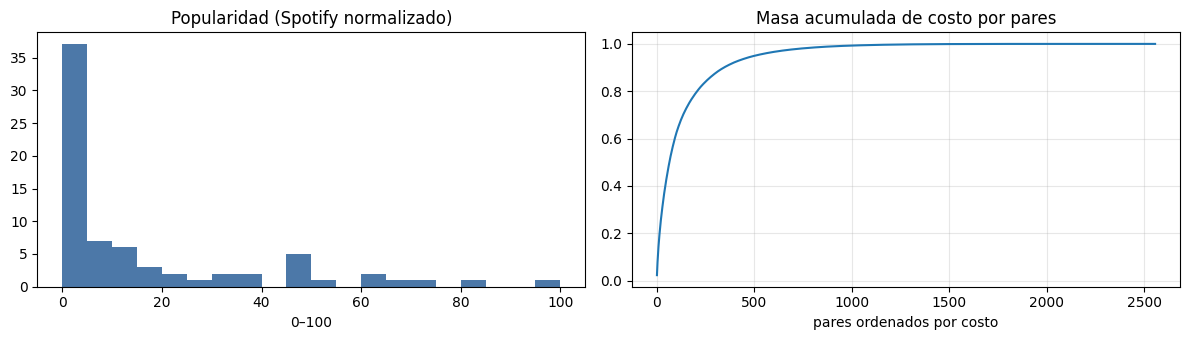

Pares que concentran 90 / 95 / 99 % del costo: [345, 503, 911] de 2556


In [6]:
import matplotlib.pyplot as plt, numpy as np
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(data.artists['pop'], bins=20, color='#4C78A8'); ax[0].set_title('Popularidad (Spotify normalizado)'); ax[0].set_xlabel('0–100')
C_ = cost_matrix(data, cfg); v = np.sort(C_[np.triu_indices(len(C_), 1)])[::-1]
ax[1].plot(np.cumsum(v) / v.sum()); ax[1].set_title('Masa acumulada de costo por pares'); ax[1].set_xlabel('pares ordenados por costo'); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
print('Pares que concentran 90 / 95 / 99 % del costo:', [int(np.searchsorted(np.cumsum(v)/v.sum(), q)) + 1 for q in (.9, .95, .99)], 'de', len(v))

**Lectura.** La normalización por el máximo deja a casi la mitad de los artistas con popularidad cercana a 0 y concentra el costo en pocos pares. Eso justifica dos decisiones del modelo: (i) en la fase 2 se modelan solo los pares que cubren el 97 % del costo, y (ii) una fase 3 de pulido incorpora todos los pares. La sensibilidad a la transformación de popularidad (`raiz`, `log`) se analiza en la sección 7.

## 4. Evaluación independiente y línea base
La función `evaluate` y `check_schedule` **no usan el solver**: miden cualquier grilla (la real o la óptima) y verifican todas las restricciones. Así la solución no se juzga con las mismas ecuaciones que la produjeron.

In [7]:
# ----------------------------------------------------------------------------
# 3. Evaluación independiente (sirve para la grilla real y para la óptima)
# ----------------------------------------------------------------------------
def baseline_schedule(data: Data) -> pd.DataFrame:
    a = data.artists
    return pd.DataFrame({"id": a["id"], "day": a["day0"], "stage": a["stage0"], "start": a["start0"]})


def _aligned(sch: pd.DataFrame, data: Data) -> pd.DataFrame:
    return sch.set_index("id").loc[data.artists["id"]].reset_index()


def overlap_hours(sch: pd.DataFrame, data: Data) -> np.ndarray:
    s = _aligned(sch, data)
    day = s["day"].values
    st = s["start"].values.astype(float)
    en = st + data.artists["dur"].values
    same = day[:, None] == day[None, :]
    ov = np.minimum(en[:, None], en[None, :]) - np.maximum(st[:, None], st[None, :])
    ov = np.where(same, np.clip(ov, 0, None), 0) / 60.0
    np.fill_diagonal(ov, 0)
    return ov


def day_attractiveness(sch: pd.DataFrame, data: Data, cfg: Config) -> np.ndarray:
    s = _aligned(sch, data)
    f = pop_factor(data, cfg) * 100.0
    return np.array([f[s["day"].values == d].sum() for d in range(len(data.days))])


def evaluate(sch: pd.DataFrame, data: Data, cfg: Config, C: np.ndarray | None = None) -> dict:
    C = cost_matrix(data, cfg) if C is None else C
    ov = overlap_hours(sch, data)
    conflict = float(np.triu(C * ov, 1).sum())
    P = day_attractiveness(sch, data, cfg)
    return {
        "conflicto": conflict,
        "pares_solapados": int((np.triu(ov, 1) > 0).sum()),
        "pares_solapados_relevantes": int(((np.triu(ov, 1) > 0) & (C > 0.05)).sum()),
        "atractivo_por_dia": P,
        "desequilibrio": float(P.max() - P.min()),
    }


def top_conflicts(sch: pd.DataFrame, data: Data, cfg: Config, n: int = 10) -> pd.DataFrame:
    C = cost_matrix(data, cfg)
    ov = overlap_hours(sch, data)
    s = _aligned(sch, data)
    rows = []
    for i, j in zip(*np.nonzero(np.triu(ov, 1))):
        rows.append({
            "Artista 1": data.artists["name"][i], "Artista 2": data.artists["name"][j],
            "Día": data.days["label"][s["day"][i]],
            "Escenarios": f"{s['stage'][i]} / {s['stage'][j]}",
            "Min. solapados": int(round(ov[i, j] * 60)),
            "Costo": C[i, j] * ov[i, j],
        })
    df = pd.DataFrame(rows)
    return df.sort_values("Costo", ascending=False).head(n).reset_index(drop=True) if len(df) else df


def check_schedule(sch: pd.DataFrame, data: Data, cfg: Config) -> list[str]:
    """Verifica TODAS las restricciones sobre una grilla. Lista vacía = factible."""
    v = []
    a, st, dy = data.artists, data.stages.set_index("name"), data.days
    s = _aligned(sch, data)
    if s["id"].duplicated().any() or len(s) != len(a):
        v.append("Cada artista debe aparecer exactamente una vez.")
    dem = demand_vector(data, cfg)
    for i, r in s.iterrows():
        d = int(r["day"])
        if not (0 <= d < len(dy)) or data.avail[i, d] != 1:
            v.append(f"{a['name'][i]}: día no disponible.")
            continue
        if r["stage"] not in st.index:
            v.append(f"{a['name'][i]}: escenario inexistente.")
            continue
        op = max(dy["open"][d], st.loc[r["stage"], "open"])
        cl = min(dy["close"][d], st.loc[r["stage"], "close"])
        if r["start"] < op or r["start"] + a["dur"][i] > cl:
            v.append(f"{a['name'][i]}: fuera de la ventana horaria del escenario.")
        if a["hl"][i] == 1 and r["start"] < cfg.headliner_min_start:
            v.append(f"{a['name'][i]}: headliner antes de las {cfg.headliner_min_start // 60}:{cfg.headliner_min_start % 60:02d}.")
        if cfg.use_capacity and dem[i] > st.loc[r["stage"], "cap"] * cfg.cap_scale * (1 + cfg.capacity_tol) + 1e-9:
            v.append(f"{a['name'][i]}: demanda {dem[i]:,.0f} supera capacidad de {r['stage']}.")
    for d in range(len(dy)):
        for sname in st.index:
            g = s[(s["day"] == d) & (s["stage"] == sname)].sort_values("start")
            prep = st.loc[sname, "prep"] + cfg.prep_extra
            idx = g.index.tolist()
            for k in range(len(idx) - 1):
                i, j = idx[k], idx[k + 1]
                if g["start"][j] < g["start"][i] + a["dur"][i] + prep:
                    v.append(f"{dy['label'][d]} · {sname}: {a['name'][i]} → {a['name'][j]} no respeta el montaje ({prep} min).")
        g = s[s["day"] == d]
        lo, hi = max(0, dy["min_art"][d] - cfg.art_delta), dy["max_art"][d] + cfg.art_delta
        if not (lo <= len(g) <= hi):
            v.append(f"{dy['label'][d]}: {len(g)} artistas (permitido {lo}–{hi}).")
        nh = int(a["hl"][g.index].sum())
        if nh < dy["min_hl"][d]:
            v.append(f"{dy['label'][d]}: {nh} headliners (mínimo {dy['min_hl'][d]}).")
        if cfg.max_headliners_day is not None and nh > cfg.max_headliners_day:
            v.append(f"{dy['label'][d]}: {nh} headliners (máximo {cfg.max_headliners_day}).")
    if cfg.coverage_block > 0:
        for d in range(len(dy)):
            for sname in st.index:
                lo_ = max(dy["open"][d], st.loc[sname, "open"])
                hi_ = min(dy["close"][d], st.loc[sname, "close"])
                g = s[(s["day"] == d) & (s["stage"] == sname)]
                for b0, b1 in coverage_blocks(lo_, hi_, cfg.coverage_block):
                    if not ((g["start"] >= b0) & (g["start"] < b1)).any():
                        v.append(f"{dy['label'][d]} · {sname}: sin shows que arranquen entre "
                                 f"{b0 // 60:02d}:{b0 % 60:02d} y {(b1 // 60) % 24:02d}:{b1 % 60:02d} (escenario vacío).")
    if not cfg.flexible_days:
        for i, r in s.iterrows():
            if a["day0"][i] >= 0 and r["day"] != a["day0"][i]:
                v.append(f"{a['name'][i]}: modo fijo exige mantener el día real.")
    if cfg.max_imbalance is not None:
        # misma aritmética entera que usa el modelo, para que la verificación sea exacta
        fi = np.round(pop_factor(data, cfg) * 1000).astype(int)
        Pd = [int(fi[s["day"].values == d].sum()) for d in range(len(dy))]
        if max(Pd) - min(Pd) > _imb_cap(cfg):
            v.append(f"Desequilibrio entre días {(max(Pd) - min(Pd)) / 10:.1f} supera el tope ε = {cfg.max_imbalance}.")
    return v


def _imb_cap(cfg: Config) -> int:
    """Tope de desequilibrio en las unidades enteras del modelo (popularidad·1000)."""
    return int(math.floor(cfg.max_imbalance * 10 + 1e-9))

In [8]:
# ----------------------------------------------------------------------------
# 6. Gráficos y exportación
# ----------------------------------------------------------------------------
GENRE_COLORS = {"Electrónica": "#4C78A8", "Pop": "#E45756", "Urbano": "#F58518", "Rock": "#54A24B",
                "Indie/Alternativo": "#B279A2", "Funk": "#EECA3B", "Folklore": "#9D755D",
                "Cumbia": "#72B7B2", "Otros": "#BAB0AC"}


def gantt_figure(sch: pd.DataFrame, data: Data, day: int, title: str = ""):
    import matplotlib.pyplot as plt
    a = data.artists.set_index("id")
    stages = list(data.stages["name"])
    g = sch[sch["day"] == day]
    fig, ax = plt.subplots(figsize=(13, 0.9 * len(stages) + 1.2))
    for r in g.itertuples():
        y = stages.index(r.stage)
        dur = a.loc[r.id, "dur"]
        ax.barh(y, dur, left=r.start, height=0.7, color=GENRE_COLORS.get(a.loc[r.id, "genre"], "#888"),
                edgecolor="black" if a.loc[r.id, "hl"] else "white", linewidth=2 if a.loc[r.id, "hl"] else 0.8)
        ax.text(r.start + dur / 2, y, a.loc[r.id, "name"], ha="center", va="center", fontsize=6.5,
                color="white", clip_on=True, rotation=0 if dur >= 60 else 90)
    ax.set_yticks(range(len(stages)))
    ax.set_yticklabels(stages)
    ax.invert_yaxis()
    lo, hi = int(data.days["open"][day]), int(data.days["close"][day])
    ax.set_xlim(lo, hi)
    ticks = list(range(lo - lo % 60 + 60, hi + 1, 60))
    ax.set_xticks(ticks)
    ax.set_xticklabels([f"{(t // 60) % 24:02d}:00" for t in ticks], fontsize=8)
    ax.grid(axis="x", alpha=0.25)
    ax.set_title(f"{data.days['label'][day]} {title}", fontsize=11, loc="left")
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in GENRE_COLORS.values()]
    ax.legend(handles, GENRE_COLORS.keys(), ncol=9, fontsize=7, loc="upper center",
              bbox_to_anchor=(0.5, -0.12), frameon=False)
    fig.tight_layout()
    return fig


def to_excel_bytes(sch: pd.DataFrame, data: Data, cfg: Config, res: Result) -> bytes:
    buf = io.BytesIO()
    tabla = full_schedule(sch, data).drop(columns=["start", "day"])
    resumen = pd.DataFrame({
        "Indicador": ["Conflicto grilla real", "Conflicto grilla optimizada", "Reducción (%)",
                      "Desequilibrio real", "Desequilibrio optimizado", "Estado solver", "Gap (%)"],
        "Valor": [round(res.baseline["conflicto"], 4), round(res.metrics["conflicto"], 4),
                  round(100 * (res.reduccion_conflicto or 0), 1), round(res.baseline["desequilibrio"], 1),
                  round(res.metrics["desequilibrio"], 1), res.status, round(100 * (res.gap or 0), 2)]})
    with pd.ExcelWriter(buf, engine="openpyxl") as w:
        tabla.to_excel(w, sheet_name="Grilla_optimizada", index=False)
        resumen.to_excel(w, sheet_name="Resumen", index=False)
        top_conflicts(sch, data, cfg, 30).to_excel(w, sheet_name="Conflictos_residuales", index=False)
    return buf.getvalue()

Violaciones de la grilla REAL: ninguna  (la grilla anunciada cumple todas las reglas del modelo)
{'conflicto': 0.398, 'pares_solapados': 70, 'pares_solapados_relevantes': 2, 'atractivo_por_dia': array([464.7, 371.3, 328. ]), 'desequilibrio': 136.7}


,Artista 1,Artista 2,Día,Escenarios,Min. solapados,Costo
0,Djo,Balu Brigada,Viernes 13,Flow / Alternative,60,0.072842
1,Addison Rae,TV Girl,Sabado 14,Flow / Alternative,60,0.069832
2,Chappell Roan,RIIZE,Sabado 14,Flow / Alternative,60,0.038117
3,Sabrina Carpenter,Ben Böhmer,Domingo 15,Flow / Perrys,65,0.035750
4,"Tyler, The Creator",Yosuke Yukimatsu,Viernes 13,Flow / Perrys,75,0.026078
5,Lorde,RØZ,Viernes 13,Samsung / Perrys,45,0.019637


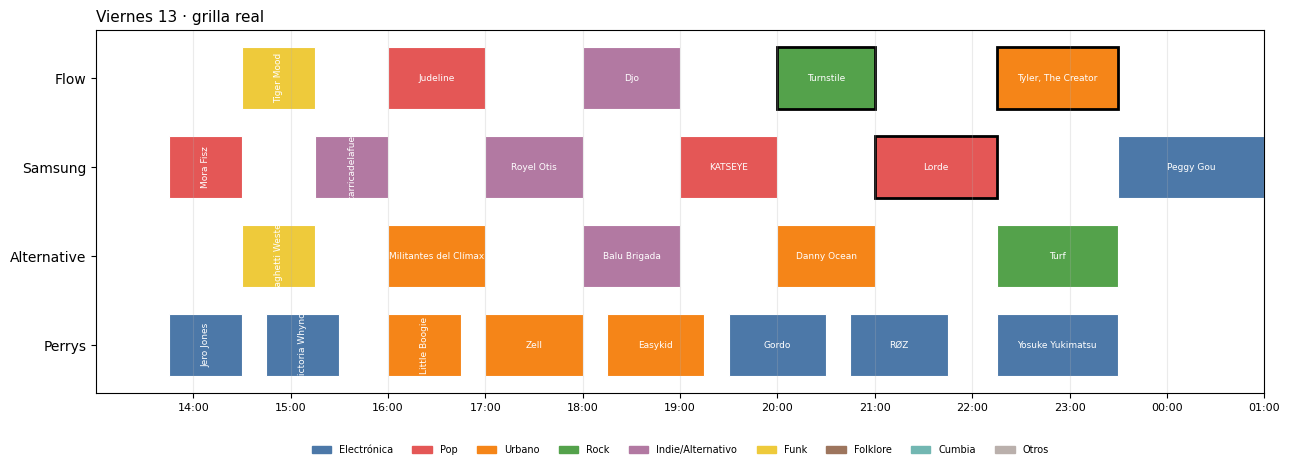

In [9]:
base = baseline_schedule(data)
print('Violaciones de la grilla REAL:', check_schedule(base, data, cfg) or 'ninguna  (la grilla anunciada cumple todas las reglas del modelo)')
b = evaluate(base, data, cfg)
print({k: (np.round(v, 3) if hasattr(v, '__len__') else round(v, 4)) for k, v in b.items()})
display(top_conflicts(base, data, cfg, 6))
gantt_figure(base, data, 0, '· grilla real'); plt.show()

## 5. Modelo CP-SAT
Implementación de la formulación de la sección 1. Puntos clave del código:
- `x[i,d,s]` solo se crea si es *posible* (disponibilidad, capacidad, horario): reduce el modelo antes de resolver.
- Un único `start[i]` por artista compartido por todos sus intervalos opcionales.
- Las binarias `same` y el `AddMinEquality` implementan las restricciones 8 y 9.
- **Matheurística** (`solve_best`): F1 días reales fijos → F2 días libres con pares podados → F3 días fijados por F2 y todos los pares. Cada fase usa a la anterior como solución inicial (*hint*). Probamos que el modelo completo de entrada no converge bien; esta descomposición sí.

In [10]:
# ----------------------------------------------------------------------------
# 4. Modelo CP-SAT
# ----------------------------------------------------------------------------
@dataclass
class Result:
    status: str
    schedule: pd.DataFrame | None
    metrics: dict
    baseline: dict
    obj_norm: float | None
    bound_norm: float | None
    gap: float | None
    seconds: float
    n_vars: int = 0
    n_pairs: int = 0
    message: str = ""
    model_obj: float | None = None   # objetivo interno del solver (pares podados, grilla de slots)
    phases: list = field(default_factory=list)

    @property
    def ok(self) -> bool:
        return self.schedule is not None

    @property
    def reduccion_conflicto(self) -> float | None:
        if not self.ok or self.baseline["conflicto"] <= 0:
            return None
        return 1 - self.metrics["conflicto"] / self.baseline["conflicto"]


def _normalizers(data: Data, cfg: Config):
    base = baseline_schedule(data)
    b = evaluate(base, data, cfg)
    conf0 = max(b["conflicto"], 1e-9)
    P = b["atractivo_por_dia"]
    imb0 = max(b["desequilibrio"], 0.05 * P.mean(), 1e-9)
    return b, conf0, imb0


def solve(data: Data, cfg: Config, time_limit: float = 60, workers: int | None = None,
          use_hint: bool = True, seed: int = 1, log: bool = False,
          hint: pd.DataFrame | None = None, fix_days: np.ndarray | None = None) -> Result:
    t0 = time.time()
    workers = workers or 8   # >1 activa las búsquedas LNS de CP-SAT, clave para el modo flexible
    a, stg, dy = data.artists, data.stages, data.days
    A, D, S = len(a), len(dy), len(stg)
    slot = cfg.slot
    base_metrics, conf0, imb0 = _normalizers(data, cfg)

    L = [math.ceil(x / slot) for x in a["dur"]]
    prep = [math.ceil((p + cfg.prep_extra) / slot) for p in stg["prep"]]
    cap = stg["cap"].values * cfg.cap_scale * (1 + cfg.capacity_tol)
    dem = demand_vector(data, cfg)
    hl_slot = math.ceil(cfg.headliner_min_start / slot)
    op = np.zeros((D, S), int)
    cl = np.zeros((D, S), int)
    for d in range(D):
        for s in range(S):
            op[d, s] = math.ceil(max(dy["open"][d], stg["open"][s]) / slot)
            cl[d, s] = math.floor(min(dy["close"][d], stg["close"][s]) / slot)

    # combinaciones (artista, día, escenario) permitidas
    allowed = {}
    for i in range(A):
        for d in range(D):
            if not data.avail[i, d]:
                continue
            if not cfg.flexible_days and a["day0"][i] >= 0 and d != a["day0"][i]:
                continue
            if fix_days is not None and d != int(fix_days[i]):
                continue
            for s in range(S):
                if cfg.use_capacity and dem[i] > cap[s] + 1e-9:
                    continue
                lo = max(op[d, s], hl_slot if a["hl"][i] else 0)
                if cl[d, s] - L[i] < lo:
                    continue
                allowed[i, d, s] = True
        if not any(k[0] == i for k in allowed):
            return Result("INFACTIBLE_DATOS", None, {}, base_metrics, None, None, None, time.time() - t0,
                          message=f"'{a['name'][i]}' no tiene ninguna combinación día/escenario/horario posible "
                                  f"(revisar disponibilidad, capacidad, demanda u horarios).")

    m = cp_model.CpModel()
    x = {k: m.NewBoolVar(f"x_{k[0]}_{k[1]}_{k[2]}") for k in allowed}
    start = []
    for i in range(A):
        ks = [k for k in allowed if k[0] == i]
        lo = min(max(op[d, s], hl_slot if a["hl"][i] else 0) for _, d, s in ks)
        hi = max(cl[d, s] - L[i] for _, d, s in ks)
        start.append(m.NewIntVar(int(lo), int(hi), f"start_{i}"))
        m.AddExactlyOne(x[k] for k in ks)

    per_stage = {(d, s): [] for d in range(D) for s in range(S)}
    for (i, d, s), var in x.items():
        m.Add(start[i] >= int(max(op[d, s], hl_slot if a["hl"][i] else 0))).OnlyEnforceIf(var)
        m.Add(start[i] + L[i] <= int(cl[d, s])).OnlyEnforceIf(var)
        per_stage[d, s].append(m.NewOptionalFixedSizeIntervalVar(start[i], L[i] + prep[s], var, f"iv_{i}_{d}_{s}"))
    for lst in per_stage.values():
        if len(lst) > 1:
            m.AddNoOverlap(lst)

    yd = {(i, d): sum(x[i, d, s] for s in range(S) if (i, d, s) in x) for i in range(A) for d in range(D)}
    for d in range(D):
        n_d = sum(yd[i, d] for i in range(A))
        m.Add(n_d >= max(0, int(dy["min_art"][d]) - cfg.art_delta))
        m.Add(n_d <= int(dy["max_art"][d]) + cfg.art_delta)
        n_h = sum(yd[i, d] for i in range(A) if a["hl"][i] == 1)
        m.Add(n_h >= int(dy["min_hl"][d]))
        if cfg.max_headliners_day is not None:
            m.Add(n_h <= cfg.max_headliners_day)

    # --- cobertura: ningún escenario queda vacío durante un bloque largo ---
    if cfg.coverage_block > 0:
        inb = {}
        for d in range(D):
            for s_ in range(S):
                for b0, b1 in coverage_blocks(int(op[d, s_] * slot), int(cl[d, s_] * slot), cfg.coverage_block):
                    zs = []
                    for i in range(A):
                        if (i, d, s_) not in x:
                            continue
                        if (b0 > (cl[d, s_] - L[i]) * slot) or (b1 <= op[d, s_] * slot):
                            continue
                        if (i, b0, b1) not in inb:
                            v_ = m.NewBoolVar(f"inb_{i}_{b0}_{b1}")
                            m.Add(start[i] * slot >= b0).OnlyEnforceIf(v_)
                            m.Add(start[i] * slot <= b1 - 1).OnlyEnforceIf(v_)
                            inb[i, b0, b1] = v_
                        z = m.NewBoolVar(f"z_{i}_{d}_{s_}_{b0}")
                        m.AddImplication(z, x[i, d, s_])
                        m.AddImplication(z, inb[i, b0, b1])
                        zs.append(z)
                    if zs:
                        m.AddBoolOr(zs)

    dayexpr = [sum(d * yd[i, d] for d in range(D)) for i in range(A)]
    days_possible = [{d for (ii, d, _s) in allowed if ii == i} for i in range(A)]

    # --- conflictos: costo * minutos solapados (mismo día) ---
    C = cost_matrix(data, cfg)
    iu = np.triu_indices(A, 1)
    vals = C[iu]
    order = np.argsort(-vals)
    cum = np.cumsum(vals[order]) / max(vals.sum(), 1e-12)
    keep_n = int(np.searchsorted(cum, cfg.pair_mass)) + 1
    keep = {(int(iu[0][k]), int(iu[1][k])) for k in order[:keep_n]}
    terms, n_pairs = [], 0
    for i in range(A):
        for j in range(i + 1, A):
            if (i, j) not in keep:
                continue
            w = int(round(C[i, j] * (slot / 60.0) * SCALE * cfg.w_conf / conf0))
            if w <= 0 or not (days_possible[i] & days_possible[j]):
                continue
            same = m.NewBoolVar(f"same_{i}_{j}")
            m.Add(dayexpr[i] == dayexpr[j]).OnlyEnforceIf(same)
            m.Add(dayexpr[i] != dayexpr[j]).OnlyEnforceIf(same.Not())
            ub = min(L[i], L[j])
            mm = m.NewIntVar(-200, ub, f"mm_{i}_{j}")
            m.AddMinEquality(mm, [L[i], L[j], start[i] + L[i] - start[j], start[j] + L[j] - start[i]])
            ov = m.NewIntVar(0, ub, f"ov_{i}_{j}")
            m.Add(ov >= mm).OnlyEnforceIf(same)
            terms.append(w * ov)
            n_pairs += 1

    # --- equilibrio de atractivo entre días (rango max-min) ---
    f = pop_factor(data, cfg) * 1000
    Pd = [sum(int(round(f[i])) * yd[i, d] for i in range(A)) for d in range(D)]
    mx = m.NewIntVar(0, int(f.sum()) + 1, "Pmax")
    mn = m.NewIntVar(0, int(f.sum()) + 1, "Pmin")
    m.AddMaxEquality(mx, Pd)
    m.AddMinEquality(mn, Pd)
    if cfg.max_imbalance is not None:
        m.Add(mx - mn <= _imb_cap(cfg))
    imb0_int = imb0 * 10.0  # pop_factor*100 -> *1000 : factor 10
    coef_e = int(round(cfg.w_equil * SCALE / imb0_int))
    obj = sum(terms) + coef_e * (mx - mn)
    m.Minimize(obj)

    # --- pista inicial: grilla real (o la dada) redondeada a la grilla de slots ---
    if use_hint:
        h = hint if hint is not None else baseline_schedule(data)
        h = _aligned(h, data)
        snames = list(stg["name"])
        for i in range(A):
            d0, s0 = int(h["day"][i]), (snames.index(h["stage"][i]) if h["stage"][i] in snames else -1)
            for (ii, d, s), var in x.items():
                if ii == i:
                    m.AddHint(var, 1 if (d == d0 and s == s0) else 0)
            m.AddHint(start[i], int(round(h["start"][i] / slot)))

    solver = cp_model.CpSolver()
    solver.parameters.max_time_in_seconds = float(time_limit)
    solver.parameters.num_workers = int(workers)
    solver.parameters.random_seed = int(seed)
    solver.parameters.log_search_progress = bool(log)
    st = solver.Solve(m)
    name = solver.StatusName(st)
    secs = time.time() - t0
    if st not in (cp_model.OPTIMAL, cp_model.FEASIBLE):
        msg = ("El modelo es INFACTIBLE con estos parámetros: relajá restricciones (capacidad, "
               "mín. de artistas por día, disponibilidad)." if st == cp_model.INFEASIBLE
               else "No se encontró solución en el tiempo dado; aumentá el límite de tiempo.")
        return Result(name, None, {}, base_metrics, None, None, None, secs, len(x), n_pairs, msg)

    rows = []
    for i in range(A):
        for (ii, d, s), var in x.items():
            if ii == i and solver.Value(var):
                rows.append({"id": a["id"][i], "day": d, "stage": stg["name"][s],
                             "start": int(solver.Value(start[i]) * slot)})
    sch = pd.DataFrame(rows)
    met = evaluate(sch, data, cfg)
    obj_norm = cfg.w_conf * met["conflicto"] / conf0 + cfg.w_equil * met["desequilibrio"] / imb0
    mobj = solver.ObjectiveValue() / SCALE
    bound = solver.BestObjectiveBound() / SCALE
    gap = abs(mobj - bound) / max(abs(mobj), 1e-9)
    return Result(name, sch, met, base_metrics, obj_norm, bound, gap, secs, len(x), n_pairs, model_obj=mobj)


def result_from_schedule(sch: pd.DataFrame, data: Data, cfg: Config, status: str = "PISTA") -> Result:
    """Evalúa una grilla ya existente con los parámetros de cfg y la empaqueta como Result.
    Si la grilla viola alguna restricción de cfg devuelve un Result sin grilla (no utilizable)."""
    base_metrics, conf0, imb0 = _normalizers(data, cfg)
    if sch is None or check_schedule(sch, data, cfg):
        return Result("PISTA_INFACTIBLE", None, {}, base_metrics, None, None, None, 0.0)
    sch = _aligned(sch, data)[["id", "day", "stage", "start"]]
    met = evaluate(sch, data, cfg)
    obj = cfg.w_conf * met["conflicto"] / conf0 + cfg.w_equil * met["desequilibrio"] / imb0
    return Result(status, sch, met, base_metrics, obj, None, None, 0.0)


def solve_best(data: Data, cfg: Config, time_limit: float = 90, workers: int | None = None,
               seed: int = 1, log: bool = False, hint: pd.DataFrame | None = None) -> Result:
    """Estrategia recomendada (matheurística de 3 fases sobre el mismo modelo CP-SAT).

    Modo fijo   : una sola resolución exacta con todos los pares.
    Modo flexible:
      F1  días reales fijos, pares podados            -> solución inicial rápida
      F2  días libres,       pares podados (pair_mass) -> decide días/escenarios/horarios
      F3  días fijados por F2, TODOS los pares         -> pulido exacto del residuo de costo
    Se devuelve siempre la mejor grilla (por objetivo evaluado con todos los pares).

    hint (arranque en caliente): si se pasa una grilla ya optimizada, se salta F1, se usa como
    solución de partida en F2 y, si es factible para cfg, se garantiza que el resultado NO es peor
    que ella. Así los escenarios de sensibilidad no dependen de la suerte del solver.
    """
    t0 = time.time()
    phases = []

    def rec(name, r):
        phases.append({"Fase": name, "Estado": r.status, "Pares modelados": r.n_pairs,
                       "Obj. interno": None if r.model_obj is None else round(r.model_obj, 4),
                       "Gap (%)": None if r.gap is None else round(100 * r.gap, 1),
                       "Seg.": round(r.seconds, 1)})

    def keep_best(r):
        """Compara con la pista: si la pista es factible y mejor, se queda con la pista."""
        if hint is None:
            return r
        h = result_from_schedule(hint, data, cfg)
        if h.ok and (not r.ok or h.obj_norm < r.obj_norm - 1e-12):
            phases.append({"Fase": "Pista conservada (el solver no la mejoró)", "Estado": h.status,
                           "Pares modelados": None, "Obj. interno": None, "Gap (%)": None, "Seg.": 0.0})
            h.phases, h.seconds, h.gap = phases, time.time() - t0, r.gap
            return h
        return r

    if not cfg.flexible_days:
        r = solve(data, replace(cfg, pair_mass=1.0), time_limit, workers, seed=seed, log=log, hint=hint)
        rec("Exacta (días fijos, todos los pares)", r)
        r.phases = phases
        return keep_best(r)

    if hint is None:
        r1 = solve(data, replace(cfg, flexible_days=False), time_limit * 0.15, workers, seed=seed, log=log)
        rec("F1 · días reales fijos", r1)
        h2 = r1.schedule if r1.ok else None
    else:
        r1 = Result("OMITIDA", None, {}, {}, None, None, None, 0.0)
        h2 = hint
    t2 = time_limit * (0.65 if (r1.ok or hint is not None) else 0.80)
    r2 = solve(data, cfg, t2, workers, seed=seed, log=log, hint=h2)
    rec("F2 · días libres (pares podados)", r2)
    best = r2 if r2.ok else (r1 if r1.ok else r2)
    if not best.ok:
        best.phases = phases
        return keep_best(best)
    if r1.ok and r2.ok and r1.obj_norm < r2.obj_norm:
        best = r1
    fd = _aligned(best.schedule, data)["day"].values
    left = max(5.0, time_limit - (time.time() - t0))
    r3 = solve(data, replace(cfg, pair_mass=1.0), left, workers, seed=seed, log=log,
               hint=best.schedule, fix_days=fd)
    rec("F3 · pulido (días fijados, todos los pares)", r3)
    if r3.ok and r3.obj_norm <= best.obj_norm + 1e-12:
        best = r3
    final = best
    final.phases = phases
    final.seconds = time.time() - t0
    # el gap informado es el de la fase que decide días/escenarios/horarios (F2)
    if r2.ok:
        final.gap, final.bound_norm = r2.gap, r2.bound_norm
    return keep_best(final)


def full_schedule(sch: pd.DataFrame, data: Data) -> pd.DataFrame:
    """Tabla legible: artista, día, escenario, horario."""
    a = data.artists
    df = sch.merge(a[["id", "name", "genre", "hl", "pop", "dur"]], on="id")
    df["Día"] = df["day"].map(lambda d: data.days["label"][d])
    df["Inicio"] = df["start"].map(lambda t: f"{(t // 60) % 24:02d}:{t % 60:02d}")
    df["Fin"] = (df["start"] + df["dur"]).map(lambda t: f"{(t // 60) % 24:02d}:{t % 60:02d}")
    df["Headliner"] = df["hl"].map({1: "Sí", 0: ""})
    out = df.sort_values(["day", "stage", "start"])
    return out[["Día", "stage", "Inicio", "Fin", "name", "genre", "Headliner", "pop", "start", "day"]].rename(
        columns={"stage": "Escenario", "name": "Artista", "genre": "Género", "pop": "Popularidad"}).reset_index(drop=True)

In [12]:
# ----------------------------------------------------------------------------
# 5. Sensibilidad y robustez
# ----------------------------------------------------------------------------
def _row(label: str, r: Result, extra: dict | None = None) -> dict:
    if r.ok:
        row = {"Escenario": label, "Estado": r.status,
               "Reducción conflicto vs real (%)": round(100 * r.reduccion_conflicto, 1),
               "Desequilibrio entre días": round(r.metrics["desequilibrio"], 1),
               "Pares solapados relevantes": r.metrics["pares_solapados_relevantes"],
               "Objetivo (1 = grilla real)": round(r.obj_norm, 3),
               "Gap (%)": None if r.gap is None else round(100 * r.gap, 1), "Seg.": round(r.seconds, 1)}
    else:
        row = {"Escenario": label, "Estado": r.status, "Reducción conflicto vs real (%)": np.nan,
               "Desequilibrio entre días": np.nan, "Pares solapados relevantes": np.nan,
               "Objetivo (1 = grilla real)": np.nan, "Gap (%)": np.nan, "Seg.": round(r.seconds, 1)}
    row.update(extra or {})
    return row


def scenario_table(data: Data, base: Config, scenarios: dict, time_limit: float = 20, workers: int | None = None,
                   base_result: Result | None = None, seeds: tuple = (1,),
                   hint: pd.DataFrame | None = None) -> pd.DataFrame:
    """Re-optimiza bajo variaciones de parámetros. Cada fila compara contra la grilla REAL
    evaluada con los mismos parámetros (por eso la reducción % es comparable entre escenarios).

    base_result : resultado de la corrida principal. Si se pasa,
        · el escenario sin cambios ({}) reutiliza ese resultado (la fila Base coincide con la sección 6);
        · todos los demás arrancan desde esa grilla (arranque en caliente) y nunca devuelven
          algo peor que ella cuando sigue siendo factible.
    seeds : semillas a probar por escenario; se informa la mejor y el rango de reducción entre semillas.
    hint  : grilla de arranque si no se pasa base_result (por ejemplo, una optimizada con otros parámetros).
    """
    if base_result is not None and base_result.ok:
        hint = base_result.schedule
    rows = []
    for label, changes in scenarios.items():
        cfg = replace(base, **changes)
        if not changes and base_result is not None:
            rows.append(_row(label, base_result, {"Reducción mín–máx entre semillas (%)": "corrida principal"}))
            continue
        runs = [solve_best(data, cfg, time_limit=time_limit, workers=workers, seed=s, hint=hint) for s in seeds]
        ok = [r for r in runs if r.ok]
        best = min(ok, key=lambda r: r.obj_norm) if ok else runs[0]
        extra = {}
        if len(seeds) > 1:
            red = [100 * r.reduccion_conflicto for r in ok]
            extra["Reducción mín–máx entre semillas (%)"] = f"{min(red):.1f} – {max(red):.1f}" if red else "—"
        rows.append(_row(label, best, extra))
    return pd.DataFrame(rows)


def epsilon_frontier(data: Data, cfg: Config, eps_list, time_limit: float = 60, workers: int | None = None,
                     hint: pd.DataFrame | None = None, seed: int = 1) -> pd.DataFrame:
    """Frontera conflicto vs. equilibrio por el método de ε-restricción:
        min conflicto   s.a.   desequilibrio entre días <= ε
    Se recorre ε de MENOR a MAYOR y cada corrida arranca desde la mejor grilla anterior. Como una grilla
    factible para un ε también lo es para cualquier ε mayor, el conflicto queda NO creciente por
    construcción: la frontera es monótona aunque el solver no llegue al óptimo en cada punto."""
    rows, best_sch = [], hint
    for eps in sorted(eps_list):
        c = replace(cfg, w_equil=0.0, max_imbalance=float(eps))
        r = solve_best(data, c, time_limit=time_limit, workers=workers, seed=seed, hint=best_sch)
        if r.ok:
            best_sch = r.schedule
        rows.append(_row(f"ε = {eps}", r, {"ε (tope de desequilibrio)": eps}))
    return pd.DataFrame(rows)


def seed_study(data: Data, cfg: Config, seeds=(1, 2, 3), time_limit: float = 120,
               workers: int | None = None) -> tuple[pd.DataFrame, Result]:
    """Corre la optimización principal con varias semillas: mide la variabilidad del método
    (es una matheurística con tiempo límite) y devuelve la mejor corrida para usar como base."""
    runs = [(s, solve_best(data, cfg, time_limit=time_limit, workers=workers, seed=s)) for s in seeds]
    tab = pd.DataFrame([_row(f"semilla {s}", r) for s, r in runs])
    ok = [r for _, r in runs if r.ok]
    best = min(ok, key=lambda r: r.obj_norm) if ok else runs[0][1]
    return tab, best


def robustness(data: Data, cfg: Config, sch: pd.DataFrame, n: int = 300, sigma: float = 0.3, seed: int = 0) -> pd.DataFrame:
    """Perturba multiplicativamente (lognormal) los costos de similitud y mide cuánto de la mejora
    sobre la grilla real sobrevive. Evaluación fuera de muestra: la grilla NO se vuelve a optimizar."""
    rng = np.random.default_rng(seed)
    C0 = cost_matrix(data, cfg)
    base = baseline_schedule(data)
    ov_s, ov_b = overlap_hours(sch, data), overlap_hours(base, data)
    rows = []
    for _ in range(n):
        N = rng.lognormal(mean=-sigma ** 2 / 2, sigma=sigma, size=C0.shape)
        N = np.triu(N, 1)
        N = N + N.T
        C = C0 * N
        c_opt = np.triu(C * ov_s, 1).sum()
        c_base = np.triu(C * ov_b, 1).sum()
        rows.append({"conflicto_optimo": c_opt, "conflicto_real": c_base, "reduccion_%": 100 * (1 - c_opt / c_base)})
    return pd.DataFrame(rows)

## 6. Resolución y resultados

In [13]:
# Se corre la optimización con varias semillas: CP-SAT con límite de tiempo no es determinístico,
# así que se mide la variabilidad del método y se usa la MEJOR corrida como solución base.
seeds_tab, res = seed_study(data, cfg, seeds=SEEDS, time_limit=TIME_LIMIT)
display(seeds_tab)
print('Mejor corrida:', res.status, '|', f'{res.seconds:.0f} s')
display(pd.DataFrame(res.phases))
assert res.ok, res.message
viol = check_schedule(res.schedule, data, cfg)
print('Verificación independiente:', 'CUMPLE TODAS LAS RESTRICCIONES' if not viol else viol)

,Escenario,Estado,Reducción conflicto vs real (%),Desequilibrio entre días,Pares solapados relevantes,Objetivo (1 = grilla real),Gap (%),Seg.
0,semilla 1,FEASIBLE,92.5,0.0,0,0.075,0.0,120.1
1,semilla 2,FEASIBLE,91.8,0.6,0,0.082,100.0,120.1
2,semilla 3,FEASIBLE,92.2,0.0,0,0.078,0.0,120.1


Mejor corrida: FEASIBLE | 120 s


,Fase,Estado,Pares modelados,Obj. interno,Gap (%),Seg.
0,F1 · días reales fijos,OPTIMAL,208,0.2000,0.0,3.1
1,F2 · días libres (pares podados),OPTIMAL,631,0.0000,0.0,47.8
2,"F3 · pulido (días fijados, todos los pares)",FEASIBLE,694,0.0779,100.0,69.2


Verificación independiente: CUMPLE TODAS LAS RESTRICCIONES


In [14]:
kpi = pd.DataFrame({
    'Grilla real': [res.baseline['conflicto'], res.baseline['pares_solapados_relevantes'], res.baseline['desequilibrio']],
    'Grilla optimizada': [res.metrics['conflicto'], res.metrics['pares_solapados_relevantes'], res.metrics['desequilibrio']]},
    index=['Conflicto total (costo·horas)', 'Pares relevantes solapados', 'Desequilibrio de atractivo entre días']).round(3)
display(kpi)
print(f'Reducción del conflicto: {100*res.reduccion_conflicto:.1f} %')
print('Atractivo por día  real:', res.baseline['atractivo_por_dia'].round(0), ' óptima:', res.metrics['atractivo_por_dia'].round(0))

,Grilla real,Grilla optimizada
Conflicto total (costo·horas),0.398,0.03
Pares relevantes solapados,2.000,0.00
Desequilibrio de atractivo entre días,136.700,0.00


Reducción del conflicto: 92.5 %
Atractivo por día  real: [465. 371. 328.]  óptima: [388. 388. 388.]


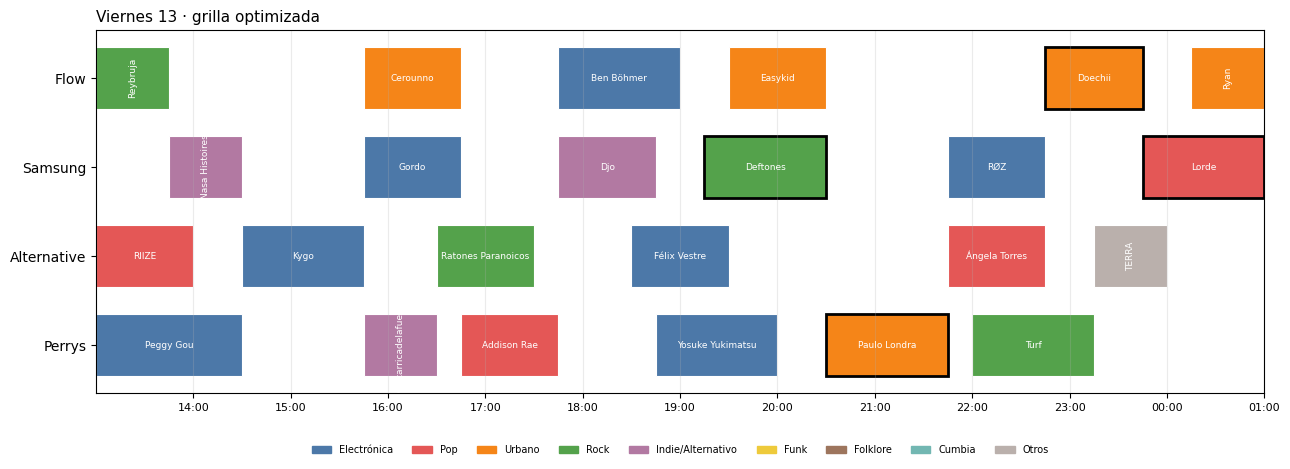

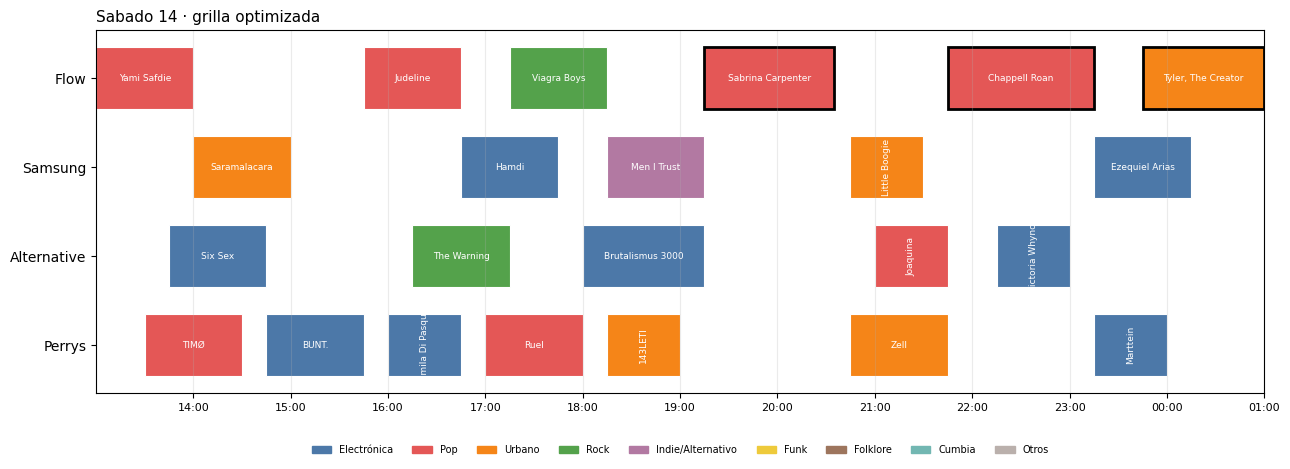

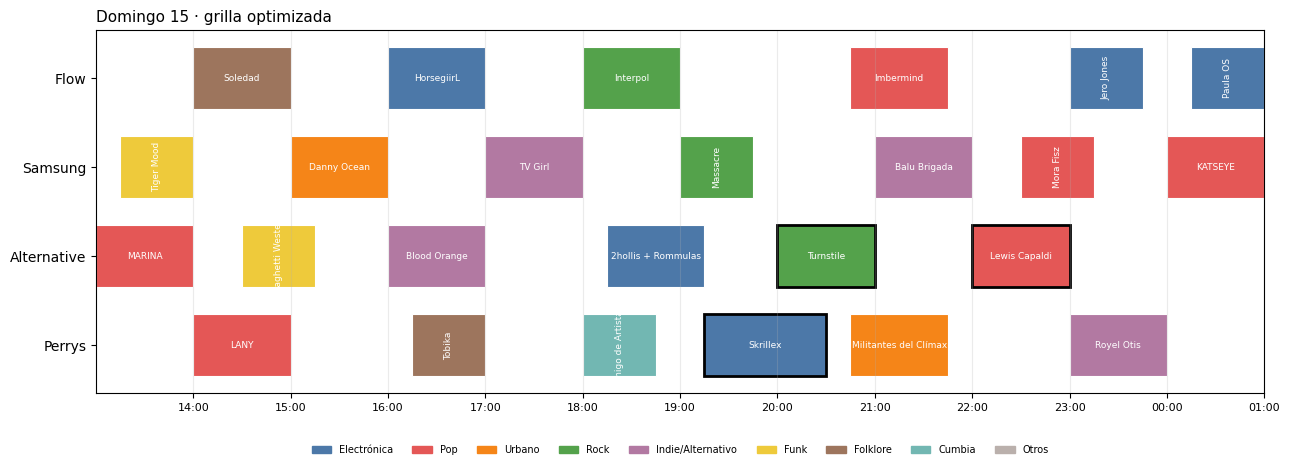

,Artista 1,Artista 2,Día,Escenarios,Min. solapados,Costo
0,Djo,Ben Böhmer,Viernes 13,Samsung / Flow,60,0.003973
1,Easykid,Deftones,Viernes 13,Flow / Samsung,60,0.003838
2,Peggy Gou,RIIZE,Viernes 13,Perrys / Alternative,60,0.002538
3,RØZ,Ángela Torres,Viernes 13,Samsung / Alternative,60,0.002226
4,Yosuke Yukimatsu,Deftones,Viernes 13,Perrys / Samsung,45,0.001688
5,Easykid,Yosuke Yukimatsu,Viernes 13,Flow / Perrys,30,0.001586


In [15]:
for d in range(len(data.days)):
    gantt_figure(res.schedule, data, d, '· grilla optimizada'); plt.show()
display(top_conflicts(res.schedule, data, cfg, 6))

In [16]:
display(full_schedule(res.schedule, data).drop(columns=['start', 'day']))

,Día,Escenario,Inicio,Fin,Artista,Género,Headliner,Popularidad
0,Viernes 13,Alternative,13:00,14:00,RIIZE,Pop,,4.7
1,Viernes 13,Alternative,14:30,15:45,Kygo,Electrónica,,49.1
2,Viernes 13,Alternative,16:30,17:30,Ratones Paranoicos,Rock,,1.7
3,Viernes 13,Alternative,18:30,19:30,Félix Vestre,Electrónica,,0.5
4,Viernes 13,Alternative,21:45,22:45,Ángela Torres,Pop,,4.2
...,...,...,...,...,...,...,...,...
67,Domingo 15,Samsung,17:00,18:00,TV Girl,Indie/Alternativo,,46.4
68,Domingo 15,Samsung,19:00,19:45,Massacre,Rock,,0.2
69,Domingo 15,Samsung,21:00,22:00,Balu Brigada,Indie/Alternativo,,12.1
70,Domingo 15,Samsung,22:30,23:15,Mora Fisz,Pop,,0.0


**Cómo leer el resultado.** La mejora se mide contra la grilla anunciada con los mismos parámetros. El gap de F2/F3 es una cota floja (típico de scheduling con linealizaciones), por lo que **no se afirma optimalidad global**: la evidencia de calidad es la comparación contra la línea base, la verificación independiente de restricciones y la robustez de la sección 7.

**Variabilidad del método.** La tabla de semillas muestra cuánto cambia el resultado entre corridas con el mismo tiempo. El conflicto suele ser estable y el desequilibrio entre días es el término más variable: hay muchas grillas con conflicto casi igual y equilibrio muy distinto. Por eso, en la sección 7, (i) la fila *Base* reutiliza esta corrida, (ii) todos los escenarios arrancan desde esta grilla (*arranque en caliente*) y (iii) la frontera conflicto–equilibrio se calcula con ε-restricción en lugar de variar el peso.

## 7. Análisis de sensibilidad y robustez
En un modelo entero no existen precios sombra como en LP (el dual no está definido). La sensibilidad se hace **re-optimizando** bajo cada variación y comparando contra la grilla real evaluada con *esos mismos* parámetros, de modo que el porcentaje sea comparable entre escenarios. Además se estima el *valor marginal* de cada recurso (capacidad, montaje, flexibilidad) por diferencia entre escenarios.

**Control de la variabilidad del solver.** Cada escenario arranca desde la grilla de la sección 6 y, si esa grilla sigue siendo factible con los nuevos parámetros, el resultado *nunca es peor que ella* (`solve_best(..., hint=...)`). Así las diferencias entre escenarios reflejan el cambio de parámetros y no la suerte de cada corrida.

### 7.1 Frontera de compromiso conflicto vs. equilibrio (método ε-restricción)
En lugar de variar el peso `w_equil` (que con un solver no convergido da curvas no monótonas), se resuelve

$$\min\ \text{conflicto}\quad \text{s.a.}\quad \max_d A_d-\min_d A_d\le\varepsilon$$

para valores crecientes de $\varepsilon$. Cada punto arranca desde la mejor grilla del punto anterior: como una grilla factible para un $\varepsilon$ también lo es para cualquier $\varepsilon$ mayor, **el conflicto es no creciente por construcción**. El resultado es la frontera de Pareto aproximada: cuánto conflicto hay que aceptar por cada unidad de equilibrio entre días.

,Escenario,Estado,Reducción conflicto vs real (%),Desequilibrio entre días,Pares solapados relevantes,Objetivo (1 = grilla real),Gap (%),Seg.,ε (tope de desequilibrio)
0,ε = 2,FEASIBLE,93.3,0.0,0,0.067,0.0,90.1,2
1,ε = 5,FEASIBLE,93.6,0.0,0,0.064,0.0,90.1,5
2,ε = 10,FEASIBLE,93.7,0.0,0,0.063,0.0,90.1,10
3,ε = 20,FEASIBLE,93.7,0.0,0,0.063,0.0,90.1,20
4,ε = 40,FEASIBLE,93.8,0.0,0,0.062,0.0,90.1,40
5,ε = 70,FEASIBLE,93.8,0.0,0,0.062,0.0,90.1,70
6,ε = 100,FEASIBLE,93.9,0.0,0,0.061,0.0,90.1,100
7,ε = 140,FEASIBLE,94.0,0.0,0,0.060,0.0,90.1,140


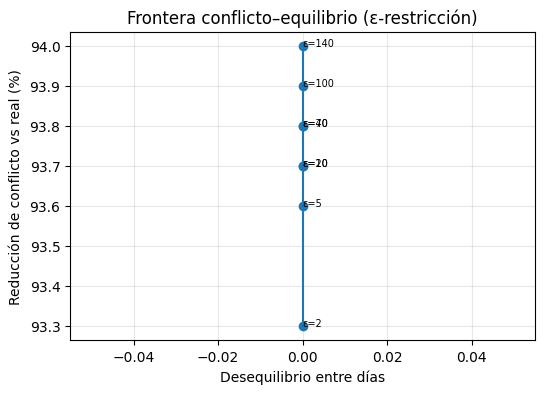

In [17]:
EPS = [2, 5, 10, 20, 40, 70, 100, 140]   # 136.7 = desequilibrio de la grilla real
frontera = epsilon_frontier(data, cfg, EPS, time_limit=TIME_SENS, hint=res.schedule)
display(frontera)
ok = frontera.dropna(subset=['Reducción conflicto vs real (%)'])
plt.figure(figsize=(6, 4)); plt.plot(ok['Desequilibrio entre días'], ok['Reducción conflicto vs real (%)'], 'o-')
for _, r in ok.iterrows():
    plt.annotate(f"ε={r['ε (tope de desequilibrio)']:g}", (r['Desequilibrio entre días'], r['Reducción conflicto vs real (%)']), fontsize=7)
plt.xlabel('Desequilibrio entre días'); plt.ylabel('Reducción de conflicto vs real (%)'); plt.grid(alpha=.3)
plt.title('Frontera conflicto–equilibrio (ε-restricción)'); plt.show()

### 7.2 Variación de parámetros operativos y de datos

In [18]:
escenarios = {
    'Base': {},
    'Montaje +15 min': {'prep_extra': 15},
    'Capacidad −10 %': {'cap_scale': 0.90},
    'Capacidad −15 % (umbral)': {'cap_scale': 0.85},
    'Sin restricción de capacidad': {'use_capacity': False},
    'Sin regla de cobertura': {'coverage_block': 0},
    'Headliners desde las 20:00': {'headliner_min_start': 1200},
    'Artistas por día ±2': {'art_delta': 2},
    'Similitud cercana = 0.8': {'sim_near': 0.8},
    'Similitud distinta = 0.3': {'sim_far': 0.3},
    'Popularidad raíz cuadrada': {'pop_transform': 'raiz'},
    'Popularidad logarítmica': {'pop_transform': 'log'},
    'Modo fijo (días reales)': {'flexible_days': False},
}
sens = scenario_table(data, cfg, escenarios, time_limit=TIME_SENS, base_result=res)
display(sens)

,Escenario,Estado,Reducción conflicto vs real (%),Desequilibrio entre días,Pares solapados relevantes,Objetivo (1 = grilla real),Gap (%),Seg.,Reducción mín–máx entre semillas (%)
0,Base,FEASIBLE,92.5,0.0,0.0,0.075,0.0,120.1,corrida principal
1,Montaje +15 min,FEASIBLE,90.5,0.0,0.0,0.095,100.0,90.1,NaN
2,Capacidad −10 %,FEASIBLE,93.4,0.0,0.0,0.066,0.0,90.1,NaN
3,Capacidad −15 % (umbral),INFACTIBLE_DATOS,NaN,NaN,NaN,NaN,NaN,0.0,NaN
4,Sin restricción de capacidad,OPTIMAL,92.5,0.0,0.0,0.075,0.0,90.1,NaN
5,Sin regla de cobertura,FEASIBLE,93.0,0.0,0.0,0.070,0.0,90.1,NaN
6,Headliners desde las 20:00,FEASIBLE,91.9,0.2,0.0,0.081,100.0,90.1,NaN
7,Artistas por día ±2,FEASIBLE,93.3,0.0,0.0,0.067,0.0,90.1,NaN
8,Similitud cercana = 0.8,FEASIBLE,93.9,0.0,0.0,0.061,0.0,90.1,NaN
9,Similitud distinta = 0.3,FEASIBLE,90.5,19.3,0.0,0.124,100.0,90.1,NaN


> ✔ **Comparabilidad.** La fila *Base* es, por construcción, la corrida de la sección 6, y cada escenario arranca desde esa grilla. Si un escenario no mejora la grilla de partida, la tabla muestra el estado `PISTA` (se conservó la grilla base, que sigue siendo factible). Reportá siempre el tiempo usado.

**Para el informe:** el escenario *Capacidad −15 %* debería salir `INFACTIBLE_DATOS`: el artista de mayor demanda deja de caber en el mayor escenario. Ese umbral es el equivalente, en un modelo entero, de un *rango de factibilidad* de LP. La comparación *Modo fijo* vs. *Base* mide el **valor de la flexibilidad** de poder mover artistas entre días. Si algún escenario termina en `FEASIBLE` con gap alto, su porcentaje es una cota inferior de lo alcanzable: mencionalo así.

**Ojo con raíz y log:** cambian la escala de los costos, así que la columna *Pares solapados relevantes* (costo > 0,05) **no es comparable** con los otros escenarios: con esas transformaciones muchos más pares superan el umbral. Compará esos escenarios solo por la reducción porcentual. Además, el costo queda menos concentrado, la poda al 97 % conserva muchos más pares y el problema es más difícil: si dan una reducción baja, probá con más tiempo antes de concluir.

### 7.3 Robustez ante error en la similitud (evaluación fuera de muestra)
La similitud por género es un proxy. Se perturba cada costo $c_{ij}$ con ruido lognormal de media 1 y se mide cuánto de la mejora sobreviva **sin re-optimizar**.

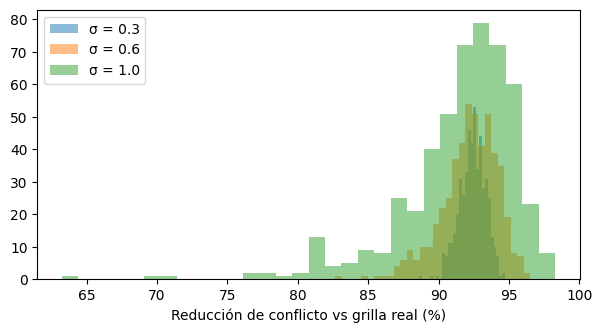

,σ ruido,Reducción media (%),Peor 5 % (%),Casos mejores que la real (%)
0,0.3,92.4,90.7,100.0
1,0.6,92.2,88.3,100.0
2,1.0,91.5,82.6,100.0


In [19]:
fig, ax = plt.subplots(figsize=(7, 3.5))
filas = []
for sg in (0.3, 0.6, 1.0):
    rb = robustness(data, cfg, res.schedule, n=500, sigma=sg)
    ax.hist(rb['reduccion_%'], bins=30, alpha=.5, label=f'σ = {sg}')
    filas.append({'σ ruido': sg, 'Reducción media (%)': rb['reduccion_%'].mean().round(1), 'Peor 5 % (%)': rb['reduccion_%'].quantile(.05).round(1),
                  'Casos mejores que la real (%)': (100*(rb['reduccion_%'] > 0).mean()).round(0)})
ax.set_xlabel('Reducción de conflicto vs grilla real (%)'); ax.legend(); plt.show()
display(pd.DataFrame(filas))

## 8. Exportación y conclusiones

In [20]:
open('grilla_optimizada_lollapalooza2026.xlsx', 'wb').write(to_excel_bytes(res.schedule, data, cfg, res))
try:
    files.download('grilla_optimizada_lollapalooza2026.xlsx')
except NameError:
    print('Guardado en la carpeta actual.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Conclusiones y limitaciones (completar con tus números)
- **Resultado principal:** reducción del conflicto vs. grilla real, pares relevantes solapados, equilibrio entre días *(tomar de la sección 6)*.
- **Valor de la flexibilidad:** diferencia entre modo fijo y flexible *(sección 7.2)*.
- **Robustez:** porcentaje de la mejora que sobrevive al ruido en la similitud *(sección 7.3)*.
- **Limitaciones a declarar:** (1) la similitud por género es un proxy, no audiencias observadas; (2) Google Trends no está cargado y la popularidad es solo Spotify normalizado por el máximo; (3) la disponibilidad de artistas es un supuesto (todos disponibles los 3 días); (4) la demanda se deriva de la popularidad con un exponente calibrado para que la grilla real sea factible; (5) no se modelan traslados entre escenarios ni preferencias reales del público; (6) la resolución es una matheurística: no hay prueba de optimalidad global.
- **Extensiones:** matriz de similitud basada en datos de escucha compartida (Last.fm), tiempos de traslado entre escenarios, optimización robusta *min-max* sobre la incertidumbre de la similitud.